# Transfer learning

Datasets (all listed in `preprocessing.DATASETS`):
- **mnist**: the original training data
- **swiss**: Swiss handwritten digits (Kaggle)
- **math**: Handwritten Math Symbols (Kaggle), digits plus + - * / ( )

In [28]:
import sys
sys.path.insert(0, "..")

import os, glob
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from hnrs.preprocessing import load_dataset, CLASSES
from hnrs.transfer import build_mix, fine_tune, compare, match_input
from hnrs.preprocess_image import preprocess_image
from hnrs.arithmetic import calculate

MODEL_PATH = "../models/lenet.keras"
FINETUNED_PATH = "../models/lenet_swiss.keras"
MIXED_PATH = "../models/lenet_mixed.keras"
SYMBOLS_PATH = "../models/lenet_symbols.keras"
CONV2D_PATH = "../models/conv2d.keras"
DENSE_PATH = "../models/dense.keras"

DIGIT_SETS = ["mnist", "swiss"]
ALL_SETS = ["mnist", "swiss", "math"]

swiss_x_train, swiss_y_train, swiss_x_test, swiss_y_test = load_dataset("swiss")
print(swiss_x_train.shape, swiss_x_test.shape)

(17247, 28, 28) (4308, 28, 28)


## 1. Original models on each dataset

In [29]:
original = tf.keras.models.load_model(MODEL_PATH)
originals = {
    "LeNet": original,
    "Conv2D": tf.keras.models.load_model(CONV2D_PATH),
    "Dense": tf.keras.models.load_model(DENSE_PATH),
}
compare(originals, ALL_SETS)

original_pred = original.predict(match_input(original, swiss_x_test), verbose=0).argmax(axis=1)
print(classification_report(swiss_y_test, original_pred, digits=4))

                          mnist    swiss     math
LeNet                     99.0%    90.9%    94.7%
Conv2D                    99.0%    92.6%    95.3%
Dense                     97.6%    82.0%    91.5%
              precision    recall  f1-score   support

           0     0.9760    0.9083    0.9409       447
           1     0.9125    0.8616    0.8863       448
           2     0.9197    0.9753    0.9467       446
           3     0.8643    0.9409    0.9010       440
           4     0.9122    0.8598    0.8852       435
           5     0.9428    0.9694    0.9559       425
           6     0.8629    0.9646    0.9109       424
           7     0.8850    0.9456    0.9143       423
           8     0.8744    0.9185    0.8959       417
           9     0.9641    0.7320    0.8322       403

    accuracy                         0.9085      4308
   macro avg     0.9114    0.9076    0.9069      4308
weighted avg     0.9114    0.9085    0.9075      4308



## 2. Fine-tune LeNet on Swiss: freeze the conv layers, retrain the dense layers

In [30]:
x, y = build_mix(["swiss"])
finetuned, _ = fine_tune(MODEL_PATH, x, y)
compare({"Fine-tuned (Swiss)": finetuned}, DIGIT_SETS)

finetuned_pred = finetuned.predict(match_input(finetuned, swiss_x_test), verbose=0).argmax(axis=1)
print(classification_report(swiss_y_test, finetuned_pred, digits=4))

Epoch 1/5
478/478 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9632 - loss: 0.1332 - val_accuracy: 0.9671 - val_loss: 0.0900
Epoch 2/5
478/478 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9791 - loss: 0.0706 - val_accuracy: 0.9759 - val_loss: 0.0742
Epoch 3/5
478/478 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9876 - loss: 0.0471 - val_accuracy: 0.9729 - val_loss: 0.0726
Epoch 4/5
478/478 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9912 - loss: 0.0338 - val_accuracy: 0.9765 - val_loss: 0.0747
Epoch 5/5
478/478 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9946 - loss: 0.0242 - val_accuracy: 0.9729 - val_loss: 0.0895
                          mnist    swiss
Fine-tuned (Swiss)        91.8%    97.4%
              precision    recall  f1-score   support

           0     0.9688    0.9732    0.9710       447
           1     0.9867    0.9955    0.9911       448
           2     0.9695    0.9978    0.9834       446
           3     0.9905    0.9455    0.9674       440
           4

## 2b. Fine-tune on a mix of MNIST and Swiss

In [31]:
x, y = build_mix(["mnist", "swiss"])
mixed, _ = fine_tune(MODEL_PATH, x, y)
compare({"Fine-tuned (mixed)": mixed}, DIGIT_SETS)

Epoch 1/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9754 - loss: 0.0871 - val_accuracy: 0.9746 - val_loss: 0.0795
Epoch 2/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9847 - loss: 0.0532 - val_accuracy: 0.9758 - val_loss: 0.0758
Epoch 3/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9894 - loss: 0.0369 - val_accuracy: 0.9758 - val_loss: 0.0822
Epoch 4/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9926 - loss: 0.0276 - val_accuracy: 0.9781 - val_loss: 0.0765
Epoch 5/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9943 - loss: 0.0218 - val_accuracy: 0.9737 - val_loss: 0.0898
                          mnist    swiss
Fine-tuned (mixed)        98.6%    96.7%


{'Fine-tuned (mixed)': {'mnist': np.float64(0.9858),
  'swiss': np.float64(0.9670380687093779)}}

## 3. Accuracy per digit, before vs after

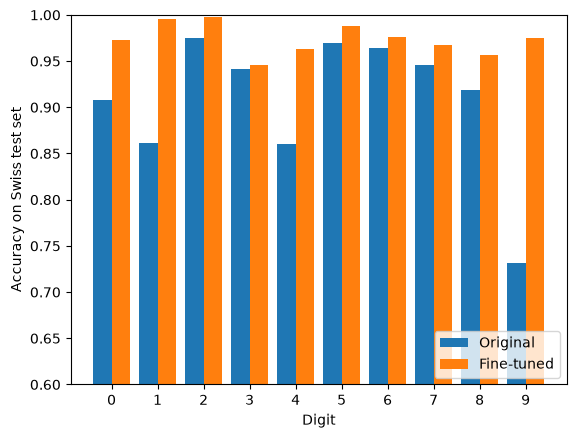

In [32]:
before = [(original_pred[swiss_y_test == d] == d).mean() for d in range(10)]
after = [(finetuned_pred[swiss_y_test == d] == d).mean() for d in range(10)]

x_pos = np.arange(10)
plt.bar(x_pos - 0.2, before, width=0.4, label="Original")
plt.bar(x_pos + 0.2, after, width=0.4, label="Fine-tuned")
plt.xticks(x_pos)
plt.ylim(0.6, 1.0)
plt.xlabel("Digit")
plt.ylabel("Accuracy on Swiss test set")
plt.legend(loc="lower right")
plt.savefig("../docs/images/lenet_transfer_per_digit.png", dpi=150)
plt.show()

## 4. Does transfer learning help more when there's less data?

In [33]:
# same LeNet as notebooks/lenet_model.ipynb, untrained
def build_model():
    keras.utils.set_random_seed(42) 
    
    model = tf.keras.models.Sequential([
        tf.keras.layers.InputLayer(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(6, kernel_size=(5, 5), activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Conv2D(16, kernel_size=(5, 5), activation='relu'),
        tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(120, activation='relu'),
        tf.keras.layers.Dense(84, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    return model

def from_scratch(n):
    model = build_model()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(match_input(model, swiss_x_train[:n]), swiss_y_train[:n], epochs=5, verbose=0)
    return model.evaluate(match_input(model, swiss_x_test), swiss_y_test, verbose=0)[1]

def with_transfer(n):
    model, _ = fine_tune(MODEL_PATH, swiss_x_train[:n], swiss_y_train[:n])
    return model.evaluate(match_input(model, swiss_x_test), swiss_y_test, verbose=0)[1]

print("train size | from scratch | transfer")
for n in [200, 1000, len(swiss_x_train)]:
    print(f"{n:10d} | {from_scratch(n):.4f}       | {with_transfer(n):.4f}")

train size | from scratch | transfer
Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9278 - loss: 0.2229 - val_accuracy: 1.0000 - val_loss: 0.0270
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9778 - loss: 0.0963 - val_accuracy: 1.0000 - val_loss: 0.0281
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9944 - loss: 0.0529 - val_accuracy: 1.0000 - val_loss: 0.0359
Epoch 4/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9944 - loss: 0.0301 - val_accuracy: 1.0000 - val_loss: 0.0413
Epoch 5/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0165 - val_accuracy: 0.9500 - val_loss: 0.0445
       200 | 0.6994       | 0.9329
Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9244 - loss: 0.2464 - val_accuracy: 0.9400 - val_loss: 0.1893
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9711 - loss: 0.0896 - val_accuracy: 0.9500 - val_loss: 0.1780
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0

## 5. My own handwriting

In [34]:
# My own handwriting photos, named by label: 0_1.jpg, 0_2.jpg, 1_1.jpg ...
paths = sorted(glob.glob("../data/handwritten/*"))
paths = [p for p in paths if p.lower().endswith((".jpg", ".jpeg", ".png"))]

names, labels, digits = [], [], []
for path in paths:
    name = os.path.basename(path)
    if not name[0].isdigit():
        print(f"{name}: not named by label, skipped")
        continue
    try:
        digits.append(preprocess_image(path))
    except ValueError:
        print(f"{name}: no digit found, skipped")
        continue
    names.append(name)
    labels.append(int(name[0]))

photos = np.array(digits)
labels = np.array(labels)

def photo_predictions(model):
    """
    returns the model's predictions for my photos
    """
    return model.predict(match_input(model, photos), verbose=0).argmax(axis=1)

original_photo_pred = photo_predictions(original)
finetuned_photo_pred = photo_predictions(finetuned)
mixed_photo_pred = photo_predictions(mixed)

print(f"{len(labels)} photos")
print(f"Original LeNet:   {(original_photo_pred == labels).mean():.1%}")
print(f"Fine-tuned LeNet: {(finetuned_photo_pred == labels).mean():.1%}")
print(f"Mixed LeNet:      {(mixed_photo_pred == labels).mean():.1%}")

# Which photos did each model get wrong?
for name, true, a, b, c in zip(names, labels, original_photo_pred, finetuned_photo_pred, mixed_photo_pred):
    if a != true or b != true or c != true:
        print(f"  {name}: true {true}, original {a}, fine-tuned {b}, mixed {c}")

29 photos
Original LeNet:   17.2%
Fine-tuned LeNet: 20.7%
Mixed LeNet:      17.2%
  20261004_105705549_iOS.jpg: true 2, original 8, fine-tuned 8, mixed 8
  20261004_105711250_iOS.jpg: true 2, original 4, fine-tuned 4, mixed 4
  20261004_105714372_iOS.jpg: true 2, original 8, fine-tuned 8, mixed 8
  20261004_105716175_iOS.jpg: true 2, original 7, fine-tuned 1, mixed 7
  20261004_105717806_iOS.jpg: true 2, original 6, fine-tuned 6, mixed 6
  20261004_105719438_iOS.jpg: true 2, original 0, fine-tuned 0, mixed 0
  20261004_105721148_iOS.jpg: true 2, original 9, fine-tuned 9, mixed 9
  20261004_105722834_iOS.jpg: true 2, original 4, fine-tuned 4, mixed 4
  20261004_105724514_iOS.jpg: true 2, original 4, fine-tuned 4, mixed 4
  20261004_105726087_iOS.jpg: true 2, original 5, fine-tuned 5, mixed 5
  20261004_105728147_iOS.jpg: true 2, original 6, fine-tuned 6, mixed 6
  20261004_105731301_iOS.jpg: true 2, original 7, fine-tuned 7, mixed 7
  20261004_105733039_iOS.jpg: true 2, original 1, fine

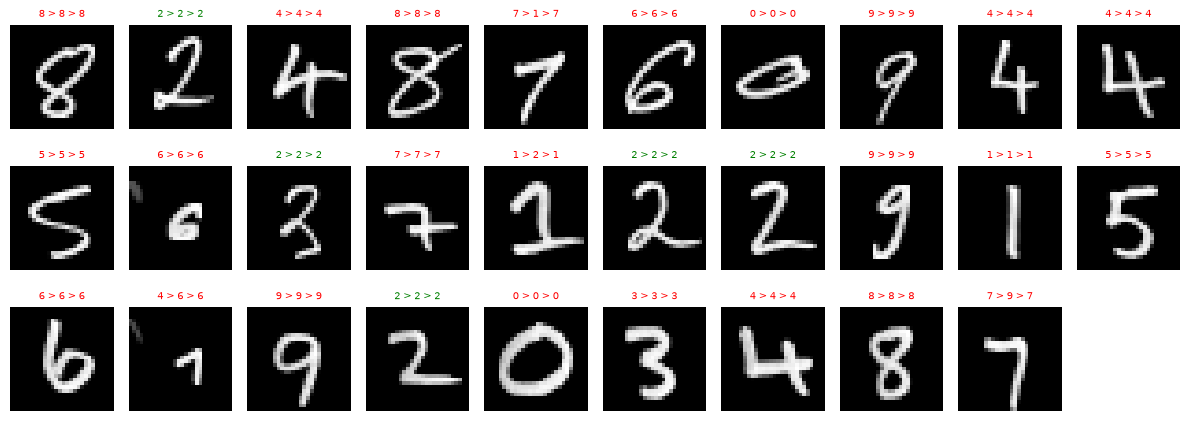

In [35]:
# Grid: preprocessed photo, with original > fine-tuned > mixed prediction
# Green = mixed model correct, red = mixed model wrong
cols = 10
rows = int(np.ceil(len(labels) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.5))
for ax in np.array(axes).flat:
    ax.axis("off")
for ax, digit, true, a, b, c in zip(np.array(axes).flat, digits, labels, original_photo_pred, finetuned_photo_pred, mixed_photo_pred):
    ax.imshow(digit, cmap="gray")
    ax.set_title(f"{a} > {b} > {c}", color="green" if c == true else "red", fontsize=7)
plt.tight_layout()
plt.savefig("../docs/images/handwritten_transfer.png", dpi=150)
plt.show()

## 6. Adding arithmetic symbols

Epoch 1/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9176 - loss: 0.3164 - val_accuracy: 0.9744 - val_loss: 0.0904
Epoch 2/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9755 - loss: 0.0828 - val_accuracy: 0.9773 - val_loss: 0.0706
Epoch 3/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9852 - loss: 0.0568 - val_accuracy: 0.9780 - val_loss: 0.0642
Epoch 4/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9905 - loss: 0.0410 - val_accuracy: 0.9794 - val_loss: 0.0613
Epoch 5/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9932 - loss: 0.0305 - val_accuracy: 0.9830 - val_loss: 0.0627
Epoch 1/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9031 - loss: 0.3320 - val_accuracy: 0.9730 - val_loss: 0.0907
Epoch 2/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9630 - loss: 0.1225 - val_accuracy: 0.9787 - val_loss: 0.0748
Epoch 3/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9732 - loss: 0.0887 - val_accuracy: 0.9801 - v

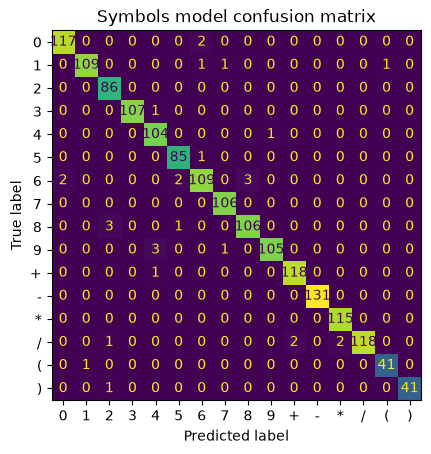

In [36]:
x, y = build_mix(["mnist", "swiss", "math"])
finals = {}
for name, base, out in [("LeNet", MODEL_PATH, SYMBOLS_PATH),
                        ("Conv2D", CONV2D_PATH, "../models/conv2d_math.keras"),
                        ("Dense", DENSE_PATH, "../models/dense_math.keras")]:
    finals[name], _ = fine_tune(base, x, y, num_classes=16, save_path=out)
compare(finals, ALL_SETS)

symbols = finals["LeNet"]

_, _, math_x_test, math_y_test = load_dataset("math")
math_pred = symbols.predict(match_input(symbols, math_x_test), verbose=0).argmax(axis=1)
print(classification_report(math_y_test, math_pred, target_names=CLASSES, digits=3))

ConfusionMatrixDisplay.from_predictions(math_y_test, math_pred, display_labels=CLASSES, colorbar=False)
plt.title("Symbols model confusion matrix")
plt.show()

In [37]:
rng = np.random.default_rng(42)

def pick_image(char):
    """
    returns a random math test image of the given character
    """
    label = CLASSES.index(char)
    return math_x_test[rng.choice(np.where(math_y_test == label)[0])]

for expression in ["12+3*4", "9-4/2", "7*8", "100/25+6"]:
    images = np.array([pick_image(c) for c in expression])
    pred = symbols.predict(match_input(symbols, images), verbose=0).argmax(axis=1)
    predicted = "".join(CLASSES[i] for i in pred)
    try:
        result = calculate(predicted)
    except ValueError as e:
        result = f"error: {e}"
    print(f"actual {expression} = {calculate(expression)} | predicted {predicted} = {result}")

actual 12+3*4 = 24 | predicted 12+3*4 = 24
actual 9-4/2 = 7.0 | predicted 9-4/2 = 7.0
actual 7*8 = 56 | predicted 7*8 = 56
actual 100/25+6 = 10.0 | predicted 100+25+6 = 131


## 7. Same fine-tuning for every model

In [38]:
x, y = build_mix(["mnist", "swiss"])

tuned = {}
for name, path in [("LeNet", MODEL_PATH), ("Conv2D", CONV2D_PATH), ("Dense", DENSE_PATH)]:
    tuned[name], _ = fine_tune(path, x, y)

compare(tuned, DIGIT_SETS)
for name, model in tuned.items():
    print(f"{name}: {model.count_params():,} parameters, my photos {(photo_predictions(model) == labels).mean():.1%}")

Epoch 1/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9754 - loss: 0.0871 - val_accuracy: 0.9746 - val_loss: 0.0795
Epoch 2/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9847 - loss: 0.0532 - val_accuracy: 0.9758 - val_loss: 0.0758
Epoch 3/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9894 - loss: 0.0369 - val_accuracy: 0.9758 - val_loss: 0.0822
Epoch 4/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9926 - loss: 0.0276 - val_accuracy: 0.9781 - val_loss: 0.0765
Epoch 5/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9943 - loss: 0.0218 - val_accuracy: 0.9737 - val_loss: 0.0898
Epoch 1/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9678 - loss: 0.1092 - val_accuracy: 0.9775 - val_loss: 0.0799
Epoch 2/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9773 - loss: 0.0756 - val_accuracy: 0.9775 - val_loss: 0.0770
Epoch 3/5
963/963 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9809 - loss: 0.0621 - val_accuracy: 0.9746 - v

## 8. Summary

In [39]:
models = {"Original": original, "Fine-tuned (Swiss)": finetuned, "Fine-tuned (mixed)": mixed, "Symbols model": symbols}
compare(models, ALL_SETS)

print()
for name, model in models.items():
    print(f"{name:22s} my photos {(photo_predictions(model) == labels).mean():.1%}")

                          mnist    swiss     math
Original                  99.0%    90.9%    94.7%
Fine-tuned (Swiss)        91.8%    97.4%    90.4%
Fine-tuned (mixed)        98.6%    96.7%    96.8%
Symbols model             98.2%    96.2%    98.1%

Original               my photos 17.2%
Fine-tuned (Swiss)     my photos 20.7%
Fine-tuned (mixed)     my photos 17.2%
Symbols model          my photos 17.2%
